# 6.2 Covariance

**Goal:** interpret covariance units and construct covariance and correlation matrices correctly.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Correlation](1_Correlation.ipynb)
2. [Covariance](2_Covariance.ipynb)
3. [Regression Analysis](3_Regression-Analysis.ipynb)
4. [Advanced Regression](4_Advanced-Regression.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Population Covariance and Sample Covariance

For variables with finite second moments, $\operatorname{Cov}(X,Y)=E[(X-\mu_X)(Y-\mu_Y)]=E[XY]-E[X]E[Y]$. For a complete finite paired population use denominator N; an IID sample unbiased covariance estimator uses n−1:
$$s_{XY}=\frac1{n-1}\sum_i(x_i-\bar x)(y_i-\bar y).$$
Its sign describes linear co-variation, and its units are the product of input units. Independent variables have zero covariance when defined; zero covariance does not generally imply independence.

**Worked example:** x=[1,2,3],y=[2,4,6] have sample covariance 2 and finite-population covariance 4/3. Denominators differ because descriptive empirical moments and unbiased estimation answer different tasks.

In [2]:
x=np.array([1.,2.,3.]);y=2*x
sample_cov=np.sum((x-x.mean())*(y-y.mean()))/(len(x)-1)
print("Sample covariance:",sample_cov,"population covariance:",np.mean((x-x.mean())*(y-y.mean())))
assert np.isclose(sample_cov,2)

Sample covariance: 2.0 population covariance: 1.3333333333333333


## 2. Covariance Matrix

For a vector X, its covariance matrix Σ has entries Cov(Xᵢ,Xⱼ), is symmetric, and is positive semidefinite: $v^T\Sigma v=\operatorname{Var}(v^TX)\ge0$. Diagonal entries are variances. Perfectly redundant features can make it singular; inversion then needs a justified restriction or regularization.

For rows as observations and columns as features, the sample matrix is $S=X_c^TX_c/(n-1)$. NumPy's `cov(...,rowvar=False)` matches that layout. Pairwise deletion with different missing-data subsets can produce a matrix that is not positive semidefinite; a common complete-case computation avoids that particular inconsistency but may introduce selection bias.

Under a linear transform Y=AX+b, Cov(Y)=AΣAᵀ. Adding constants changes no covariance; multiplying one variable by 100 multiplies its covariance with another by 100 and its own variance by 10000.

In [3]:
X=np.column_stack([x,y,np.array([3.,1.,2.])])
centered=X-X.mean(axis=0)
S=centered.T@centered/(len(X)-1)
print("Covariance matrix:\n",S,"eigenvalues:",np.linalg.eigvalsh(S))
assert np.allclose(S,np.cov(X,rowvar=False))
assert np.linalg.eigvalsh(S).min()>-1e-10

Covariance matrix:
 [[ 1.   2.  -0.5]
 [ 2.   4.  -1. ]
 [-0.5 -1.   1. ]] eigenvalues: [2.64655302e-16 7.08712153e-01 5.29128785e+00]


## 3. Correlation Matrix and Covariance vs. Correlation

If all variances are positive, $R=D^{-1}SD^{-1}$ where D contains feature SDs. R is dimensionless, has ones on the diagonal, and lies in [−1,1] entrywise. It measures standardized linear association; S retains scale. Neither matrix captures all higher-order or nonlinear dependence.

**Example:** converting a feature from meters to centimeters changes covariance entries but leaves correlation with unchanged features the same. If an SD is zero, the corresponding correlations are undefined; substituting zero hides that distinction.

In PCA, a covariance-based analysis emphasizes high-variance units while a correlation-based analysis effectively standardizes features. Neither is automatically right: the scientific interpretation determines whether original scale should matter. Regularized covariance estimates can help when feature count is comparable to or exceeds sample size.

Correlation matrix:
 [[ 1.   1.  -0.5]
 [ 1.   1.  -0.5]
 [-0.5 -0.5  1. ]]


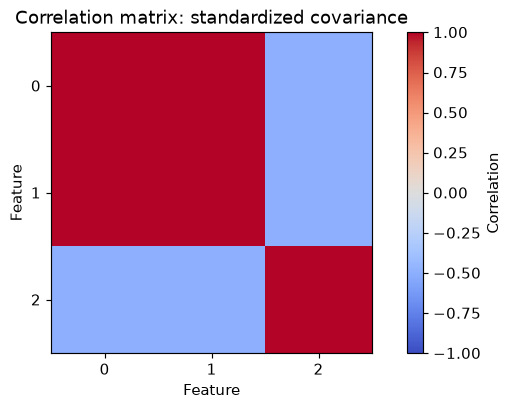

In [4]:
sd=np.sqrt(np.diag(S));R=S/np.outer(sd,sd)
print("Correlation matrix:\n",R)
assert np.allclose(R,np.corrcoef(X,rowvar=False))
fig,ax=plt.subplots();im=ax.imshow(R,vmin=-1,vmax=1,cmap="coolwarm")
ax.set(title="Correlation matrix: standardized covariance",xlabel="Feature",ylabel="Feature",xticks=[0,1,2],yticks=[0,1,2])
fig.colorbar(im,ax=ax,label="Correlation");fig.tight_layout();plt.show()

## AI/ML application and interpretation

Covariance matrices underlie PCA, multivariate Gaussian models, uncertainty propagation, and feature analysis. Estimate scaling and covariance on training data, inspect conditioning, and avoid treating a matrix inverse as reliable when observations are few or features redundant. Correlation heatmaps show association rather than causal structure.

## Practice

1. What are the units of covariance between height in meters and mass in kilograms?
2. How does multiplying height by 100 change covariance and correlation with mass?
3. Why must a covariance matrix be positive semidefinite?
4. What happens when one feature is an exact multiple of another?

## Solutions

1. Meter-kilograms.
2. Covariance multiplies by 100; correlation is unchanged for positive scaling.
3. Every quadratic form is the variance of a linear combination, which cannot be negative.
4. The matrix can become singular, so naive inversion fails; recognize redundancy or use a justified regularization method.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](3_Regression-Analysis.ipynb).